# Tan Tien Hock (ID: 6968437D) — Singapore Property Reviews: Defensible LDA Topic Modelling Workflow

**Individual objective:** Discover and compare the main concerns raised in Singapore property reviews, and how these concerns differ by region, property type, reviewer type, and time.

## Table of Contents

1. [Setup & Library Imports](#1-setup--library-imports)
2. [Load Raw Dataset](#2-load-raw-dataset)
3. [Data Quality Assessment](#3-data-quality-assessment)
4. [Data Cleaning](#4-data-cleaning)
5. [Exploratory Data Analysis](#5-exploratory-data-analysis)
6. [Text Preprocessing (Tokenisation, Stopwords, Lemmatisation, Bigrams)](#6-text-preprocessing)
7. [Corpus & Model Selection](#7-corpus--model-selection)
8. [Final LDA Model Fitting & Topic Assignment](#8-final-model-fitting)
9. [Topic Validation — Representative Reviews & Prevalence](#9-topic-validation)
10. [Business Comparison — Topic Shares by Region / Property Type / Reviewer Type](#10-business-comparison)
    - 10a. [Topic Comparison by Year (2024-2026)](#10a-topic-comparison-by-year-2024-2026)
    - 10a-ii. [Top 30 Representative Reviews by Year](#10a-ii-top-30-representative-reviews-by-year)
    - 10b. [Standalone Topic Comparison by Region](#10b-standalone-topic-comparison-by-region)
    - 10b-ii. [Top 30 Representative Reviews by Region](#10b-ii-top-30-representative-reviews-by-region)
11. [Word Clouds & Interactive pyLDAvis Visualisation](#11-word-clouds--pyldavis)
    - 11.5. [Sentence-Embedding Sanity Check (Optional)](#115-sentence-embedding-sanity-check)
12. [Write-up & Hand-off Checklist](#12-write-up--hand-off-checklist)

---

## Workflow and Evidence to Capture

1. **Business question:** Which concerns are most prevalent, and how do they differ by region / property type / reviewer type / year?
2. **Data understanding:** Show source, coverage, fields, duplicates, missingness, invalid dates, and category values.
3. **Preparation:** Retain raw data, create a cleaning log, remove only records that cannot support the text-analysis objective, and document every rule.
4. **Model:** Test 5–8 topics with three fixed seeds; select by mean *c_v* coherence, then verify interpretability and topic size. Fit **one** global model only — never retrain separate models per Year or Region, since that breaks topic-ID comparability.
5. **Evaluation:** Show top words, representative reviews, topic prevalence, and normalised comparisons by region, property type, reviewer type, and year — including a year-over-year stability check and the top-30 most confident reviews per year/region as review-level evidence.
6. **Recommendation:** Translate the final named topics into an agency action; state the synthetic-sampling limitation.


## 1. Setup & Library Imports

Install required packages (run once, then restart the kernel if this is a fresh environment) and import all libraries needed for data handling, NLP preprocessing, and LDA topic modelling.

- **pandas / numpy** — data manipulation
- **matplotlib / seaborn** — visualisation
- **nltk** — tokenisation, stopwords, POS tagging, lemmatisation
- **gensim** — dictionary, corpus, LDA model, coherence scoring, bigram phrase detection

Fixed random seeds (`42, 84, 126`) and topic candidates (`5–8`) are defined here so every downstream cell references the same reproducible settings.


In [1]:
# Install once if needed (run in a separate environment, then restart the kernel).

!pip install pandas numpy matplotlib seaborn nltk gensim pyLDAvis wordcloud
from pathlib import Path
from collections import Counter
import math, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel
from gensim.models.phrases import Phrases, Phraser
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag, word_tokenize

RANDOM_SEEDS = [42, 84, 126]
TOPIC_CANDIDATES = range(5, 9)  # aligns to the 5-8-topic project plan
TOP_N_WORDS = 15
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_colwidth', 160)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 86.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 49.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pyLDAvis]


## 2. Load Raw Dataset

Load the final selected review CSV (kept alongside this notebook, or auto-detected via a filename pattern if not found). This preserves `raw_reviews` as an untouched reference copy — no cleaning happens yet.


In [2]:
# Load the final selected review dataset. Keep the CSV beside this notebook or set DATA_FILE explicitly.
DATA_FILE = Path('Fion_3000_Synthetic_Property_Reviews.csv')
if not DATA_FILE.exists():
    candidates = list(Path('.').glob('*Property*Review*.csv'))
    if len(candidates) != 1:
        raise FileNotFoundError('Set DATA_FILE to the one final review CSV used by the team.')
    DATA_FILE = candidates[0]
raw_reviews = pd.read_csv(DATA_FILE)
print(f'Loaded {DATA_FILE.name}: {raw_reviews.shape[0]:,} rows x {raw_reviews.shape[1]} columns')
display(raw_reviews.head(3))
print(raw_reviews.dtypes)

Loaded 3000_Synthetic_Property_Reviews.csv: 3,000 rows x 12 columns


,Review_ID,Review_Date,Property_Type,Region,Town,Reviewer_Type,Reference_Topic,Sentiment,Rating,Review_Length,Word_Count,Review_Text
0,PR0001,2024-08-08,Condominium,North-East,Punggol,Tenant,Pricing & Affordability,Positive,4,Short,19,The monthly rent is fair for the location and unit size. Our viewing took place in the late afternoon.
1,PR0002,2025-08-06,Rental Apartment,East,Tampines,Buyer,MRT & Transport,Neutral,4,Short,18,Transport access is acceptable for residents who plan their journeys. We assessed it together with other nearby options.
2,PR0003,2025-06-25,Landed Property,North,Sungei Kadut,Tenant,Location Convenience,Positive,5,Medium,30,"After comparing several properties, the area has a good mix of schools, eateries and essential amenities. It met most of our expectations. This reflects our..."


Review_ID          object
Review_Date        object
Property_Type      object
Region             object
Town               object
Reviewer_Type      object
Reference_Topic    object
Sentiment          object
Rating              int64
Review_Length      object
Word_Count          int64
Review_Text        object
dtype: object


## 3. Data Quality Assessment

Profile the raw dataset before any cleaning: check for required columns, count missing values and their percentage per column, count unique values, and check for exact duplicate rows and duplicate `Review_ID`s. Value counts for key categorical columns (Region, Property_Type, Reviewer_Type, Source, Reference_Topic) are also displayed to confirm expected categories.


In [3]:
# Data-quality evidence. Change only the OPTIONAL_COLUMNS names if the supplied dataset differs.
REQUIRED_COLUMNS = {'Review_ID', 'Review_Text', 'Review_Date'}
OPTIONAL_COLUMNS = ['Region', 'Property_Type', 'Reviewer_Type', 'Source', 'Reference_Topic']
missing_required = REQUIRED_COLUMNS - set(raw_reviews.columns)
if missing_required:
    raise ValueError(f'Missing required columns: {sorted(missing_required)}')

quality_before = pd.DataFrame({
    'missing': raw_reviews.isna().sum(),
    'missing_pct': (raw_reviews.isna().mean() * 100).round(2),
    'unique_values': raw_reviews.nunique(dropna=True)
}).sort_index()
display(quality_before)
print('Exact duplicate rows:', raw_reviews.duplicated().sum())
print('Duplicate Review_IDs:', raw_reviews['Review_ID'].duplicated().sum())
for col in [c for c in OPTIONAL_COLUMNS if c in raw_reviews.columns]:
    print(f'\n{col} value counts:')
    display(raw_reviews[col].value_counts(dropna=False).head(20).to_frame('count'))

,missing,missing_pct,unique_values
Property_Type,0,0.0,5
Rating,0,0.0,5
Reference_Topic,0,0.0,15
Region,0,0.0,5
Review_Date,0,0.0,897
Review_ID,0,0.0,3000
Review_Length,0,0.0,3
Review_Text,0,0.0,2556
Reviewer_Type,0,0.0,5
Sentiment,0,0.0,3


Exact duplicate rows: 0
Duplicate Review_IDs: 0

Region value counts:


,count
Region,
East,623
North,619
Central,594
North-East,586
West,578



Property_Type value counts:


,count
Property_Type,
HDB Resale Flat,1324
Condominium,874
Rental Apartment,382
Executive Condominium,238
Landed Property,182



Reviewer_Type value counts:


,count
Reviewer_Type,
Buyer,621
Landlord,621
Property Viewer,590
Seller,588
Tenant,580



Reference_Topic value counts:


,count
Reference_Topic,
Facilities,212
Renovation Quality,205
Property Condition,205
Security & Safety,205
Neighbourhood & Community,202
Agent Service,202
Investment & Rental Potential,201
Parking,200
Pricing & Affordability,200


## 4. Data Cleaning

Clean the dataset into a working copy (`reviews`) while keeping `raw_reviews` intact for audit purposes. Cleaning steps applied and logged in `cleaning_log`:

- Strip whitespace from all string columns and collapse repeated spaces in review text
- Parse `Review_Date` into a proper datetime, coercing invalid dates to null
- Remove records with missing `Review_ID`, unusably short review text (<3 characters), or invalid/missing `Review_Date`
- Drop duplicate `Review_ID`s, keeping the first occurrence
- Standardise category columns (blank strings → null) and derive `Year`, `Month`, `Month_Name`, `Day_of_Week` features

Every removal rule and its row impact is captured in the `cleaning_log` table for transparency.


In [4]:
# Cleaning: raw_reviews is never overwritten. Each removal is counted for the milestone evidence.
reviews = raw_reviews.copy()
string_cols = reviews.select_dtypes(include='object').columns
reviews[string_cols] = reviews[string_cols].apply(lambda s: s.str.strip())
reviews['Review_Date'] = pd.to_datetime(reviews['Review_Date'], errors='coerce')
reviews['Review_Text'] = reviews['Review_Text'].fillna('').astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()

cleaning_log = []
def keep_rows(mask, rule):
    global reviews
    removed = int((~mask).sum())
    cleaning_log.append({'rule': rule, 'rows_removed': removed, 'rows_remaining': int(mask.sum())})
    reviews = reviews.loc[mask].copy()

keep_rows(reviews['Review_ID'].notna() & reviews['Review_ID'].astype(str).ne(''), 'Remove records with no Review_ID')
keep_rows(reviews['Review_Text'].str.len().ge(3), 'Remove blank or unusably short review text')
keep_rows(reviews['Review_Date'].notna(), 'Remove records with invalid/missing Review_Date')
before = len(reviews); reviews = reviews.drop_duplicates(subset='Review_ID', keep='first').copy()
cleaning_log.append({'rule': 'Keep first occurrence of duplicate Review_ID', 'rows_removed': before-len(reviews), 'rows_remaining': len(reviews)})

# Standardise only display/comparison categories; report any nulls rather than inventing values.
for col in [c for c in OPTIONAL_COLUMNS if c in reviews.columns]:
    reviews[col] = reviews[col].replace('', pd.NA).astype('string').str.strip()

reviews['Year'] = reviews['Review_Date'].dt.year
reviews['Month'] = reviews['Review_Date'].dt.month
reviews['Month_Name'] = reviews['Review_Date'].dt.month_name().str[:3]
reviews['Day_of_Week'] = reviews['Review_Date'].dt.day_name()
cleaning_log = pd.DataFrame(cleaning_log)
display(cleaning_log)
print(f'Final analysis set: {len(reviews):,} / {len(raw_reviews):,} records')

,rule,rows_removed,rows_remaining
0,Remove records with no Review_ID,0,3000
1,Remove blank or unusably short review text,0,3000
2,Remove records with invalid/missing Review_Date,0,3000
3,Keep first occurrence of duplicate Review_ID,0,3000


Final analysis set: 3,000 / 3,000 records


## 5. Exploratory Data Analysis

Examine the cleaned dataset's date coverage (first/last review) and review volume over time (monthly trend line chart). Also break down review counts by `Region` to confirm reasonably balanced regional sample sizes before comparing topic prevalence across regions later.


,first_review,last_review
Review_Date,2024-01-01,2026-07-29


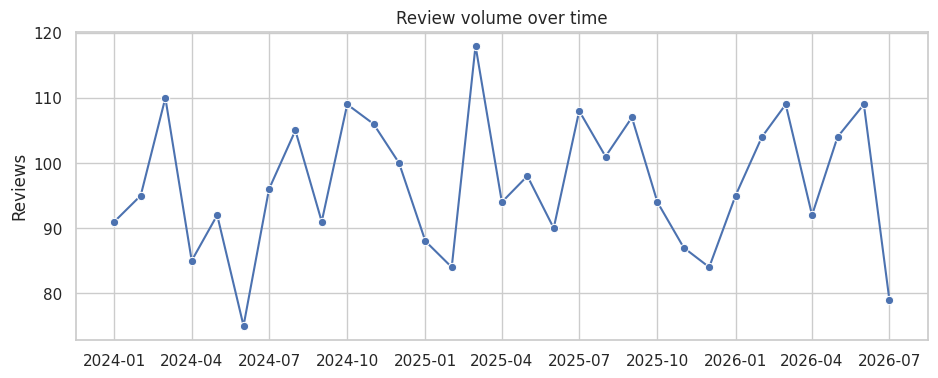

,review_count
Region,
East,623
North,619
Central,594
North-East,586
West,578


In [5]:
# Data exploration for the group milestone: coverage and volume trends.
coverage = reviews['Review_Date'].agg(['min', 'max']).rename({'min':'first_review', 'max':'last_review'}).to_frame().T
display(coverage)

monthly_counts = reviews.groupby(reviews['Review_Date'].dt.to_period('M')).size().rename('review_count').reset_index()
monthly_counts['Review_Date'] = monthly_counts['Review_Date'].dt.to_timestamp()
fig, ax = plt.subplots(figsize=(11, 4))
sns.lineplot(data=monthly_counts, x='Review_Date', y='review_count', marker='o', ax=ax)
ax.set(title='Review volume over time', xlabel='', ylabel='Reviews'); plt.show()

if 'Region' in reviews.columns:
    display(reviews.groupby('Region', dropna=False).size().rename('review_count').sort_values(ascending=False).to_frame())

## 6. Text Preprocessing

Convert raw review text into clean, lemmatised tokens suitable for topic modelling:

- Download required NLTK resources (stopwords, WordNet, tokenizer, POS tagger — both legacy and current resource names for reproducibility across NLTK versions)
- Build a combined stopword list: NLTK's base English stopwords **plus** domain-specific stopwords (e.g. "singapore", "property", "unit", "hdb") that are uninformative for every topic
- Tokenise each review (lowercase, alphabetic tokens of length ≥3, stopwords removed)
- POS-tag tokens and retain only **nouns and adjectives** — these carry the most interpretable "market concern" signal, unlike verbs/adverbs
- Lemmatise surviving tokens using WordNet POS mapping
- Drop reviews with fewer than 3 remaining tokens (too sparse to model)
- Detect and merge frequent bigrams (e.g. "public transport") using gensim's `Phrases`/`Phraser`
- Display the top 20 most frequent terms as a sanity check

> 🔧 **Update after first run:** the initial `topic_terms` output showed generic filler words ("several", "option", "nearby", "period", "need", "visit", "late", "weekemd", "weekday", "afternoon", "appointment", "immediate", "handover") repeating across 5+ of the 7 topics, which blurred topic separation. These were added to `domain_stopwords` below to sharpen topic distinctiveness — re-run the notebook from this cell onward and compare the new `topic_terms` output against the table in Section 8.


In [6]:
# Text preprocessing. The previous notebook flattened strings into characters; this cell tokenises each review correctly.
# Download both legacy and current NLTK tokeniser/tagger resource names for reproducibility.
for resource in ['stopwords', 'wordnet', 'omw-1.4', 'punkt', 'punkt_tab', 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
    nltk.download(resource, quiet=True)

base_stopwords = set(stopwords.words('english'))
domain_stopwords = {
    'singapore', 'property', 'properties', 'review', 'reviews', 'unit', 'units',
    'home', 'house', 'flat', 'condo', 'hdb', 'would', 'also', 'really', "buyer", "tenant", "resident", "expectation","point_view", "different", "common", "place","good", "area", "option", "time", "period"
    # Added after inspecting v1 topic_terms output: these appeared as top terms in
    # 5+ of 7 topics and carried no topical signal, blurring topic separation.
    'several', 'addition', 'overall', 'experience', 'expectation', 'area',
    'neighbourhood', 'anyone', 'recent', 'similar', 'smooth', 'proceed', 'useful'
}  # Add only terms that are uninformative for EVERY topic; document additions in the report.
stop_words = base_stopwords | domain_stopwords
lemmatizer = WordNetLemmatizer()

def wordnet_pos(tag):
    return {'J': 'a', 'V': 'v', 'N': 'n', 'R': 'r'}.get(tag[0], 'n')

def preprocess_review(text):
    tokens = word_tokenize(str(text).lower())
    tokens = [t for t in tokens if re.fullmatch(r'[a-z]{3,}', t) and t not in stop_words]
    tagged = pos_tag(tokens)
    # Retain nouns/adjectives: useful for interpretable market concerns.
    return [lemmatizer.lemmatize(w, wordnet_pos(tag)) for w, tag in tagged if tag.startswith(('N', 'J'))]

token_docs = [preprocess_review(text) for text in reviews['Review_Text']]
keep = np.array([len(doc) >= 3 for doc in token_docs])
print(f'Reviews retained after tokenisation: {keep.sum():,} / {len(keep):,}')
reviews_model = reviews.loc[keep].reset_index(drop=True).copy()
token_docs = [doc for doc, retain in zip(token_docs, keep) if retain]
phrases = Phrases(token_docs, min_count=max(3, math.ceil(len(token_docs) * 0.002)), threshold=8)
bigram = Phraser(phrases)
token_docs = [bigram[doc] for doc in token_docs]
display(pd.DataFrame(Counter(token for doc in token_docs for token in doc).most_common(20), columns=['term', 'frequency']))

Reviews retained after tokenisation: 3,000 / 3,000


,term,frequency
0,several,714
1,option,671
2,nearby,670
3,period,562
4,need,561
5,visit,545
6,late,534
7,weekend,531
8,weekday,522
9,afternoon,500


## 7. Corpus & Model Selection

Build **one** gensim `Dictionary` and bag-of-words `corpus` — reused consistently across every candidate model (no duplicated pipelines). Steps:

- Filter the dictionary to terms appearing in at least ~0.5% of documents and at most 80% of documents, capped at 10,000 terms
- Remove any documents that become empty after filtering, keeping `reviews_model`, `token_docs`, and `bow_corpus` synchronised
- Guard against an unusably small vocabulary/corpus after cleaning
- Train LDA models for **every combination** of topic count *k* (5–8) and random seed (42, 84, 126) — 12 runs total
- Score each run using *c_v* coherence and log-perplexity
- Aggregate results by *k* (mean/SD coherence, mean log-perplexity) and select the *k* with the highest mean coherence

The selected *k* should still be manually checked for topic interpretability and reasonable topic sizes before finalising.


In [7]:
# Build one corpus and compare 5-8 LDA models consistently. No second dictionary/model is created.
dictionary = Dictionary(token_docs)
min_document_frequency = max(2, math.ceil(len(token_docs) * 0.005))
dictionary.filter_extremes(no_below=min_document_frequency, no_above=0.80, keep_n=10_000)
bow_corpus = [dictionary.doc2bow(doc) for doc in token_docs]
nonempty = np.array([len(bow) > 0 for bow in bow_corpus])
reviews_model = reviews_model.loc[nonempty].reset_index(drop=True)
token_docs = [doc for doc, retain in zip(token_docs, nonempty) if retain]
bow_corpus = [bow for bow in bow_corpus if bow]
if len(dictionary) < 20 or len(bow_corpus) < max(TOPIC_CANDIDATES):
    raise ValueError('Vocabulary/corpus is too small after cleaning. Review stopwords and frequency thresholds.')
print(f'Model corpus: {len(bow_corpus):,} documents; vocabulary: {len(dictionary):,} terms; min_df: {min_document_frequency}')

model_runs = []
for k in TOPIC_CANDIDATES:
    for seed in RANDOM_SEEDS:
        model = LdaModel(corpus=bow_corpus, id2word=dictionary, num_topics=k, random_state=seed,
                         passes=15, iterations=150, alpha='auto', eta='auto', eval_every=None, minimum_probability=0)
        coherence = CoherenceModel(model=model, texts=token_docs, dictionary=dictionary, coherence='c_v').get_coherence()
        model_runs.append({'num_topics': k, 'seed': seed, 'coherence_c_v': coherence, 'log_perplexity': model.log_perplexity(bow_corpus)})
selection = pd.DataFrame(model_runs)
selection_summary = selection.groupby('num_topics', as_index=False).agg(
    mean_coherence=('coherence_c_v', 'mean'), sd_coherence=('coherence_c_v', 'std'), mean_log_perplexity=('log_perplexity', 'mean')
).sort_values('mean_coherence', ascending=False)
display(selection_summary.style.format({'mean_coherence':'{:.3f}', 'sd_coherence':'{:.3f}', 'mean_log_perplexity':'{:.3f}'}))
best_k = int(selection_summary.iloc[0]['num_topics'])
print(f'Selected k={best_k} by highest mean c_v coherence. Confirm topic distinctness and business meaning before finalising.')

Model corpus: 3,000 documents; vocabulary: 305 terms; min_df: 15


,num_topics,mean_coherence,sd_coherence,mean_log_perplexity
3,8,0.305,0.024,-4.708
2,7,0.291,0.028,-4.732
1,6,0.273,0.037,-4.751
0,5,0.245,0.011,-4.782


Selected k=8 by highest mean c_v coherence. Confirm topic distinctness and business meaning before finalising.


## 8. Final Model Fitting

Fit the **single final LDA model** (`best_lda`) at the selected topic count `best_k`, using more passes/iterations than the selection runs for a more stable final fit. This is the only model used in every result below.

- Extract the top 15 terms per topic into `topic_terms`
- Compute each document's full topic-probability distribution and assign a `dominant_topic` and `topic_probability` (confidence) per review
- Summarise topic sizes and their share of total reviews (`topic_summary`)
- Final business-friendly labels (`TOPIC_LABELS`) assigned below, based on reading top terms and representative reviews

> ✅ **Final labels (k=8, after stopword fix)** — confirmed from `top_terms` and representative reviews in the updated run:
>
> | Topic ID | Share | Key Terms | Label |
> |---|---|---|---|
> | 0 | 10.8% | visit, photo_online, rental, point_view | Online Listings vs. In-Person Viewing Discrepancies |
> | 1 | 5.7% | wet_market, defect, wall_fitting, agent | Unit Condition & Defects at Handover |
> | 2 | 15.4% | appointment, staff_basic, assistance_much | Viewing Appointments & Staff Assistance |
> | 3 | 14.3% | block_reach, amenity, estate, environment_feel | Estate Environment & Common Amenities |
> | 4 | 7.8% | floor_plan, hawker_daily, family, paperwork | Floor Plan Practicality & Family Suitability |
> | 5 | 14.0% | access_mall, daily_errand, station, storage | Mall/Station Access & Storage Needs |
> | 6 | 14.7% | handover, rental_demand, disappointing | Handover Timing & Rental Demand |
> | 7 | 17.4% | compare, acceptable_room, bus, car_park | Comparing Options: Facilities & Transport |
>
> ⚠️ Note: generic terms ("buyer", "tenant", "expectation", "point_view", "different_priority") still recur across several topics — likely sentence-template artifacts of the synthetic data generator. If sharper separation is needed, consider adding these to `domain_stopwords` in Section 6 and re-running, but weigh this against losing real reviewer-type signal ("buyer" vs "tenant").


In [8]:
# Fit the SINGLE final model used by every result below.
best_lda = LdaModel(corpus=bow_corpus, id2word=dictionary, num_topics=best_k, random_state=42,
                    passes=20, iterations=200, alpha='auto', eta='auto', eval_every=None, minimum_probability=0)
topic_terms = pd.DataFrame([
    {'topic_id': topic_id, 'top_terms': ', '.join(term for term, _ in best_lda.show_topic(topic_id, topn=TOP_N_WORDS))}
    for topic_id in range(best_k)
])
display(topic_terms)

topic_matrix = np.array([[prob for _, prob in best_lda.get_document_topics(bow, minimum_probability=0)] for bow in bow_corpus])
reviews_model['dominant_topic'] = topic_matrix.argmax(axis=1)
reviews_model['topic_probability'] = topic_matrix.max(axis=1)
topic_sizes = reviews_model['dominant_topic'].value_counts().sort_index().rename_axis('topic_id').reset_index(name='review_count')
topic_sizes['share_pct'] = (topic_sizes['review_count'] / len(reviews_model) * 100).round(1)
topic_summary = topic_sizes.merge(topic_terms, on='topic_id')
display(topic_summary)

# Assign final business-friendly labels AFTER the team reads the top terms and example reviews. Do not name a topic from one word.
TOPIC_LABELS = {
    0: 'Online Listings vs. In-Person Viewing Discrepancies',
    1: 'Unit Condition & Defects at Handover',
    2: 'Viewing Appointments & Staff Assistance',
    3: 'Estate Environment & Common Amenities',
    4: 'Floor Plan Practicality & Family Suitability',
    5: 'Mall/Station Access & Storage Needs',
    6: 'Handover Timing & Rental Demand',
    7: 'Comparing Options: Facilities & Transport',
}  # Confirmed against top_terms and representative reviews for k=8 (post stopword fix). Revisit if best_k changes on re-run.
reviews_model['topic_label'] = reviews_model['dominant_topic'].map(TOPIC_LABELS)

,topic_id,top_terms
0,0,"option, nearby, area, wet_market, coffee_shop, improvement, acceptable_room, period, estate_close, compare, buyer_priority, several, handover, point_view, c..."
1,1,"period, handover, several, expectation, month, disappointing, problem, access_control, feel_safe, listing, point_view, estate, water_leakage, unresolved_wee..."
2,2,"need, immediate, car_park, practical, block, several, facility, expectation, visitor_registration, environment_feel, private, inconvenient, point_view, prob..."
3,3,"late, afternoon, several, resident, issue, improvement, expectation, customer_service, viewing, month, maintenance, acceptable_room, bad, point_view, buyer_..."
4,4,"option, nearby, several, facility, expectation, amenity, block_reach, storage, feel, space, listing, area, point_view, price_reasonable, development"
5,5,"convenient, nearby, several, service, access_mall, bus, meal, location, hawker_daily, expectation, daily, option, listing, amenity_steady, rental_demand"
6,6,"weekend, appointment, observation, several, floor_plan, family, month, space, expectation, resident, quiet, point_view, estate, wall_fitting, practical_budget"
7,7,"visit, weekday, convenient, expectation, several, development, point_view, family, daily_errand, decision, recommend, access_mall, rental, return_low, space..."


,topic_id,review_count,share_pct,top_terms
0,0,350,11.7,"option, nearby, area, wet_market, coffee_shop, improvement, acceptable_room, period, estate_close, compare, buyer_priority, several, handover, point_view, c..."
1,1,362,12.1,"period, handover, several, expectation, month, disappointing, problem, access_control, feel_safe, listing, point_view, estate, water_leakage, unresolved_wee..."
2,2,387,12.9,"need, immediate, car_park, practical, block, several, facility, expectation, visitor_registration, environment_feel, private, inconvenient, point_view, prob..."
3,3,406,13.5,"late, afternoon, several, resident, issue, improvement, expectation, customer_service, viewing, month, maintenance, acceptable_room, bad, point_view, buyer_..."
4,4,378,12.6,"option, nearby, several, facility, expectation, amenity, block_reach, storage, feel, space, listing, area, point_view, price_reasonable, development"
5,5,209,7.0,"convenient, nearby, several, service, access_mall, bus, meal, location, hawker_daily, expectation, daily, option, listing, amenity_steady, rental_demand"
6,6,509,17.0,"weekend, appointment, observation, several, floor_plan, family, month, space, expectation, resident, quiet, point_view, estate, wall_fitting, practical_budget"
7,7,399,13.3,"visit, weekday, convenient, expectation, several, development, point_view, family, daily_errand, decision, recommend, access_mall, rental, return_low, space..."


## 9. Topic Validation

Sanity-check the final model by pulling the top 3 most representative original reviews for each topic (highest `topic_probability`) — do these reviews actually match the topic's top terms? Also plot topic prevalence (share of reviews per topic) as a bar chart.

A topic is questionable if it has very low support or its example reviews don't match its top terms — in that case, revisit *k* or the stopword list rather than accepting a weak topic.


,dominant_topic,topic_probability,Review_ID,Review_Text
2833,0,0.953957,PR2834,"When we visited the unit, the estate is reasonably maintained for its age. The estate is close to a wet market and coffee shop. In addition, the station is ..."
1088,0,0.953956,PR1089,"From a buyer's point of view, the estate is reasonably maintained for its age. The estate is close to a wet market and coffee shop. In addition, the rent is..."
1669,0,0.950005,PR1670,"After living here for several months, some design choices may not suit every buyer. The estate is close to a wet market and coffee shop. In addition, the pr..."
1058,1,0.941179,PR1059,"After living here for several months, the corridors were dirty and rubbish was left near the lift lobby. The listing created expectations that were not met...."
1688,1,0.941179,PR1689,"After living here for several months, the corridors were dirty and rubbish was left near the lift lobby. The listing created expectations that were not met...."
788,1,0.934381,PR0789,"After comparing several properties, the corridors were dirty and rubbish was left near the lift lobby. The listing created expectations that were not met. T..."
526,2,0.915956,PR0527,"As a tenant, transport access is acceptable for residents who plan their journeys. It may suit buyers with different priorities. Photos online looked slight..."
586,2,0.915956,PR0587,"For anyone considering this property, transport access is acceptable for residents who plan their journeys. It may suit buyers with different priorities. We..."
2638,2,0.915956,PR2639,"When we visited the unit, the home has been cared for and needs very little repair. We were satisfied with the decision. Quite okay for the right person. We..."
1446,3,0.951313,PR1447,"After living here for several months, the staff provided basic assistance without much follow-up. Peak-hour travel can still be crowded. In addition, the pr..."


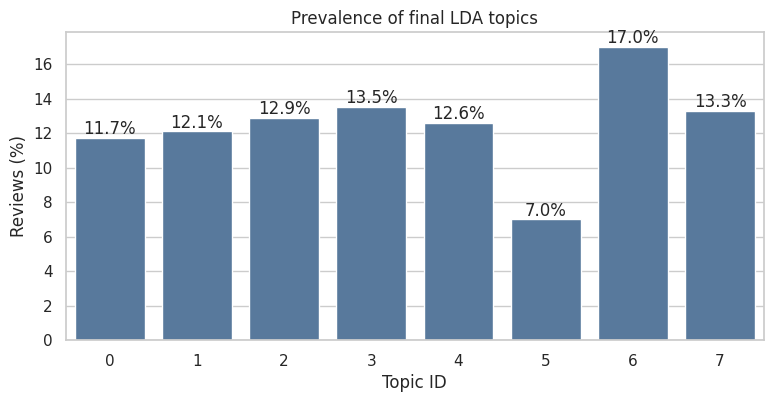

In [9]:
# Validation evidence: show the most representative original reviews for each topic.
examples = (reviews_model.sort_values(['dominant_topic', 'topic_probability'], ascending=[True, False])
            .groupby('dominant_topic', group_keys=False).head(3)
            [['dominant_topic', 'topic_probability', 'Review_ID', 'Review_Text']])
display(examples)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=topic_summary, x='topic_id', y='share_pct', color='#4C78A8', ax=ax)
ax.bar_label(ax.containers[0], fmt='%.1f%%'); ax.set(title='Prevalence of final LDA topics', ylabel='Reviews (%)', xlabel='Topic ID')
plt.show()

# A topic is questionable if it has little support or the examples do not match the top terms. Revisit k/stopwords in that case.
assert reviews_model['topic_probability'].between(0, 1).all()

## 10. Business Comparison

Compare topic mix **within** each Region using normalised (percentage) shares rather than raw counts — raw counts would be biased by uneven regional sample sizes. Visualise as a stacked bar chart of topic share by region.

The same normalised comparison is repeated for `Property_Type` and `Reviewer_Type` where those columns are available, directly answering the core business question: which concerns dominate for which segments.


topic_label,Comparing Options: Facilities & Transport,Estate Environment & Common Amenities,Floor Plan Practicality & Family Suitability,Handover Timing & Rental Demand,Mall/Station Access & Storage Needs,Online Listings vs. In-Person Viewing Discrepancies,Unit Condition & Defects at Handover,Viewing Appointments & Staff Assistance
Region,,,,,,,,
Central,13.5,14.5,12.0,15.0,6.9,9.8,14.8,13.6
East,13.5,13.2,12.8,16.9,7.4,12.4,10.9,13.0
North,12.9,14.7,12.9,15.7,6.3,12.1,13.1,12.3
North-East,11.1,13.1,13.0,18.4,6.8,13.3,12.1,12.1
West,15.6,12.1,12.3,19.0,7.4,10.7,9.3,13.5


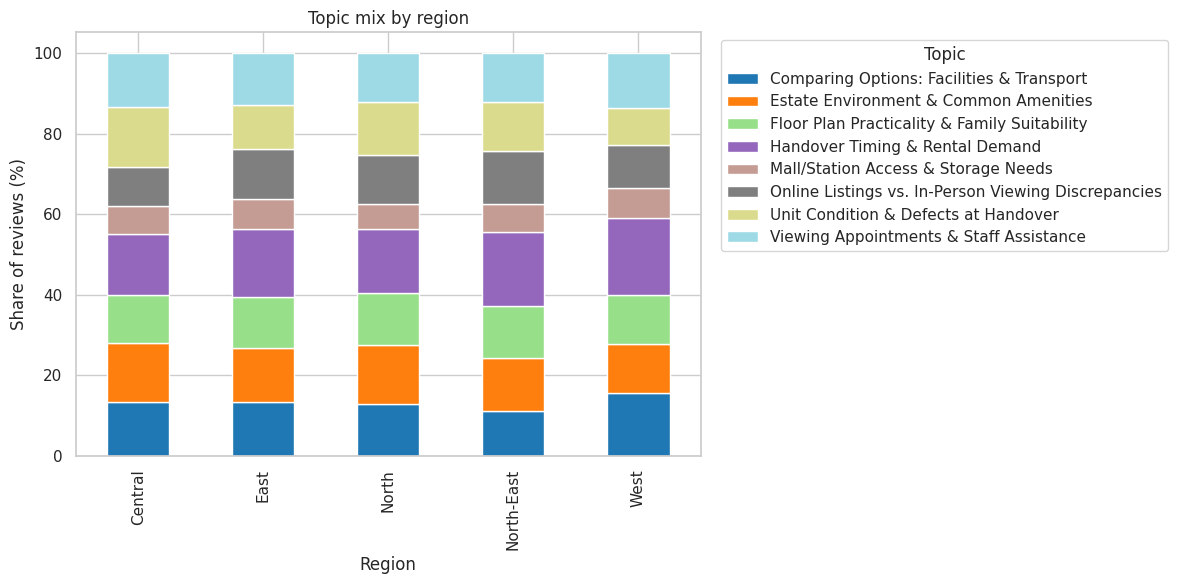

topic_label,Comparing Options: Facilities & Transport,Estate Environment & Common Amenities,Floor Plan Practicality & Family Suitability,Handover Timing & Rental Demand,Mall/Station Access & Storage Needs,Online Listings vs. In-Person Viewing Discrepancies,Unit Condition & Defects at Handover,Viewing Appointments & Staff Assistance
Property_Type,,,,,,,,
Condominium,13.0,13.6,12.7,16.4,7.3,12.1,12.7,12.1
Executive Condominium,13.4,12.6,14.3,13.4,5.5,13.4,12.6,14.7
HDB Resale Flat,13.3,13.2,12.3,17.6,6.6,12.2,11.7,13.1
Landed Property,13.2,13.7,13.2,15.9,8.2,10.4,14.8,10.4
Rental Apartment,13.9,14.9,12.0,18.8,7.9,8.4,10.2,13.9


topic_label,Comparing Options: Facilities & Transport,Estate Environment & Common Amenities,Floor Plan Practicality & Family Suitability,Handover Timing & Rental Demand,Mall/Station Access & Storage Needs,Online Listings vs. In-Person Viewing Discrepancies,Unit Condition & Defects at Handover,Viewing Appointments & Staff Assistance
Reviewer_Type,,,,,,,,
Buyer,11.9,14.7,11.0,17.4,8.2,11.9,11.6,13.4
Landlord,15.1,12.6,13.2,20.8,5.2,11.4,11.1,10.6
Property Viewer,13.7,12.2,14.2,15.8,6.6,10.5,14.2,12.7
Seller,13.9,13.4,10.7,15.3,6.8,13.6,11.9,14.3
Tenant,11.7,14.8,14.0,15.3,8.1,10.9,11.6,13.6


In [10]:
# Required business comparison: within-region topic shares (not raw counts, which are biased by regional sample size).
if 'Region' in reviews_model.columns:
    region_topic = pd.crosstab(reviews_model['Region'], reviews_model['topic_label'], normalize='index').mul(100).round(1)
    display(region_topic)
    fig, ax = plt.subplots(figsize=(12, 6))
    region_topic.plot(kind='bar', stacked=True, colormap='tab20', ax=ax)
    ax.set(title='Topic mix by region', xlabel='Region', ylabel='Share of reviews (%)')
    ax.legend(title='Topic', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout(); plt.show()

# Repeat the same normalised comparison for Property_Type or Reviewer_Type where available.
for group_col in ['Property_Type', 'Reviewer_Type']:
    if group_col in reviews_model.columns:
        display(pd.crosstab(reviews_model[group_col], reviews_model['topic_label'], normalize='index').mul(100).round(1))

## 10a. Topic Comparison by Year (2024-2026)

This section checks whether the review corpus contains enough volume in each year (2024, 2025, 2026) to support a fair year-by-year comparison, then computes the **within-year topic share** using the same single, already-fitted `best_lda` model — we do **not** retrain separate models per year, since that would make topic IDs incomparable across years.

- **Row counts per year** are shown first so a thin year (e.g. partial-year 2026 data) is flagged rather than silently trusted.
- **Topic share (%) by Year** is normalised within each year (rows sum to 100%), matching the same approach already used for Region/Property_Type/Reviewer_Type.
- **Stability score** (standard deviation of each topic's share across the three years) is reported to separate genuinely **common/stable concerns** (low std — present at a similar level every year) from **emerging or fading topics** (high std — share moves sharply year to year).


In [11]:
# Topic share by Year (2024-2026) -- reuses the single fitted best_lda model.
print("Review count per Year:")
display(reviews_model['Year'].value_counts().sort_index())

year_topic_counts = pd.crosstab(reviews_model['Year'], reviews_model['dominant_topic'])
year_topic_share = year_topic_counts.div(year_topic_counts.sum(axis=1), axis=0) * 100
year_topic_share.columns = [TOPIC_LABELS.get(t, f"Topic {t}") for t in year_topic_share.columns]
year_topic_share = year_topic_share.round(1)

print("\nTopic share (%) within each Year:")
display(year_topic_share)

topic_stability = year_topic_share.std(axis=0).sort_values().rename('std_across_years').round(2)
print("\nTopic stability across 2024-2026 (lower std = more common/stable concern; higher std = emerging/fading):")
display(topic_stability)

Review count per Year:


,count
Year,
2024,1155
2025,1153
2026,692



Topic share (%) within each Year:


,Online Listings vs. In-Person Viewing Discrepancies,Unit Condition & Defects at Handover,Viewing Appointments & Staff Assistance,Estate Environment & Common Amenities,Floor Plan Practicality & Family Suitability,Mall/Station Access & Storage Needs,Handover Timing & Rental Demand,Comparing Options: Facilities & Transport
Year,,,,,,,,
2024,12.6,12.7,12.2,13.0,11.2,7.1,18.5,12.7
2025,11.4,11.9,11.7,14.1,13.8,7.3,15.2,14.7
2026,10.7,11.3,16.0,13.6,13.0,6.2,17.3,11.8



Topic stability across 2024-2026 (lower std = more common/stable concern; higher std = emerging/fading):


,std_across_years
Estate Environment & Common Amenities,0.55
Mall/Station Access & Storage Needs,0.59
Unit Condition & Defects at Handover,0.70
Online Listings vs. In-Person Viewing Discrepancies,0.96
Floor Plan Practicality & Family Suitability,1.33
Comparing Options: Facilities & Transport,1.48
Handover Timing & Rental Demand,1.67
Viewing Appointments & Staff Assistance,2.35


## 10a-ii. Top 30 Representative Reviews by Year

Since `best_lda` only produces 5-8 topics (not 30), a "top 30 topics per year" list is not meaningful on its own -- instead, this shows the **top 30 most confidently classified reviews for each year** (2024, 2025, 2026), ranked by `topic_probability`. This gives concrete, checkable evidence of what each year's dominant concerns actually look like in reviewers' own words, beyond the aggregate percentage table above.

- Sorted by `topic_probability` (descending) **within each year**, so the strongest, least ambiguous examples surface first.
- Shows `Year`, `topic_label`, `topic_probability`, and a trimmed `Review_Text` snippet for readability.
- Use this to sanity-check the aggregate Year percentages in Section 10a -- if the top reviews for a year don't clearly match its highest-share topic, revisit the labels or cleaning rules.


In [12]:
# Top 30 most confidently classified reviews per Year (2024-2026), using the single fitted best_lda model.
pd.set_option('display.max_colwidth', 100)

top30_by_year = {}
for yr in sorted(reviews_model['Year'].dropna().unique()):
    subset = reviews_model[reviews_model['Year'] == yr].sort_values('topic_probability', ascending=False).head(30)
    top30_by_year[yr] = subset[['Review_ID', 'topic_label', 'topic_probability', 'Review_Text']].reset_index(drop=True)
    print(f"\n=== Top 30 most confident reviews — Year {yr} ===")
    display(top30_by_year[yr])


=== Top 30 most confident reviews — Year 2024 ===


,Review_ID,topic_label,topic_probability,Review_Text
0,PR1670,Online Listings vs. In-Person Viewing Discrepancies,0.950005,"After living here for several months, some design choices may not suit every buyer. The estate i..."
1,PR1128,Comparing Options: Facilities & Transport,0.947295,"From a buyer's point of view, there are many shops and services close to the development. The sh..."
2,PR0127,Estate Environment & Common Amenities,0.946742,"After living here for several months, customer service did not respond despite several follow-up..."
3,PR0212,Online Listings vs. In-Person Viewing Discrepancies,0.945312,"From a buyer's point of view, the station is reachable with one feeder bus. The estate is close ..."
4,PR2014,Handover Timing & Rental Demand,0.941607,"When we visited the unit, the condition is average for a property of this age. The sheltered wal..."
5,PR2222,Floor Plan Practicality & Family Suitability,0.941476,"After comparing several properties, getting a taxi during the morning rush can be difficult. The..."
6,PR1059,Unit Condition & Defects at Handover,0.941179,"After living here for several months, the corridors were dirty and rubbish was left near the lif..."
7,PR0332,Mall/Station Access & Storage Needs,0.937958,"When we visited the unit, daily commuting is convenient because several bus services stop nearby..."
8,PR0564,Comparing Options: Facilities & Transport,0.935113,"During our recent viewing, the estate is tidy and the landscaping is well cared for. Access to t..."
9,PR2268,Comparing Options: Facilities & Transport,0.935111,"During our recent viewing, the estate is tidy and the landscaping is well cared for. Access to t..."



=== Top 30 most confident reviews — Year 2025 ===


,Review_ID,topic_label,topic_probability,Review_Text
0,PR2002,Handover Timing & Rental Demand,0.955453,"During our recent viewing, the staff provided basic assistance without much follow-up. The nearb..."
1,PR2834,Online Listings vs. In-Person Viewing Discrepancies,0.953957,"When we visited the unit, the estate is reasonably maintained for its age. The estate is close t..."
2,PR1089,Online Listings vs. In-Person Viewing Discrepancies,0.953956,"From a buyer's point of view, the estate is reasonably maintained for its age. The estate is clo..."
3,PR1447,Estate Environment & Common Amenities,0.951313,"After living here for several months, the staff provided basic assistance without much follow-up..."
4,PR0154,Handover Timing & Rental Demand,0.947087,"From a buyer's point of view, the overall condition was poor and the rooms smelled damp. Peak-ho..."
5,PR0512,Mall/Station Access & Storage Needs,0.943782,"From a buyer's point of view, daily commuting is convenient because several bus services stop ne..."
6,PR2130,Comparing Options: Facilities & Transport,0.941835,"Based on our experience, the expected rental return is low after maintenance and other costs. Ac..."
7,PR2220,Comparing Options: Facilities & Transport,0.941834,"After comparing several properties, the expected rental return is low after maintenance and othe..."
8,PR0844,Handover Timing & Rental Demand,0.941606,"After living here for several months, several defects were not mentioned before the viewing. The..."
9,PR0290,Floor Plan Practicality & Family Suitability,0.941476,"As a tenant, the renovation workmanship appears uneven in several areas. The problems should be ..."



=== Top 30 most confident reviews — Year 2026 ===


,Review_ID,topic_label,topic_probability,Review_Text
0,PR0466,Handover Timing & Rental Demand,0.958717,"When we visited the unit, this property offers good value for a family on a practical budget. Th..."
1,PR0662,Floor Plan Practicality & Family Suitability,0.946971,"As a tenant, commuting takes longer because there is no direct train connection. The block is wi..."
2,PR0961,Estate Environment & Common Amenities,0.946742,"After living here for several months, the price is close to the current market average. Overall,..."
3,PR1188,Comparing Options: Facilities & Transport,0.941834,"After comparing several properties, the neighbourhood is convenient for daily errands and family..."
4,PR1078,Handover Timing & Rental Demand,0.941606,"During our recent viewing, the surrounding environment is generally orderly. Peak-hour travel ca..."
5,PR1918,Handover Timing & Rental Demand,0.934860,"As a tenant, the community is quiet and residents mostly keep to themselves. Overall, it was acc..."
6,PR1209,Unit Condition & Defects at Handover,0.934380,"From a buyer's point of view, the corridors were dirty and rubbish was left near the lift lobby...."
7,PR0588,Comparing Options: Facilities & Transport,0.926632,"After comparing several properties, the neighbourhood is convenient for daily errands and family..."
8,PR1446,Comparing Options: Facilities & Transport,0.926631,"After living here for several months, the agent handled the negotiation professionally without a..."
9,PR0076,Handover Timing & Rental Demand,0.926348,"As a tenant, this property offers good value for a family on a practical budget. We were satisfi..."


## 10b. Standalone Topic Comparison by Region

A dedicated, self-contained version of the Region comparison (separate from the combined Region/Property_Type/Reviewer_Type block above) so the Region result can be read, screenshotted, or exported on its own for the milestone slide.

- Uses the same `best_lda` model and `dominant_topic`/`topic_label` assignments already produced in Section 8 — no re-fitting.
- Shares are normalised **within each Region** (rows sum to 100%), so results reflect relative concern mix rather than raw review volume differences between regions.


In [13]:
# Standalone topic share by Region -- reuses the single fitted best_lda model.
region_topic_counts = pd.crosstab(reviews_model['Region'], reviews_model['dominant_topic'])
region_topic_share = region_topic_counts.div(region_topic_counts.sum(axis=1), axis=0) * 100
region_topic_share.columns = [TOPIC_LABELS.get(t, f"Topic {t}") for t in region_topic_share.columns]
region_topic_share = region_topic_share.round(1)

print("Topic share (%) within each Region:")
display(region_topic_share)

Topic share (%) within each Region:


,Online Listings vs. In-Person Viewing Discrepancies,Unit Condition & Defects at Handover,Viewing Appointments & Staff Assistance,Estate Environment & Common Amenities,Floor Plan Practicality & Family Suitability,Mall/Station Access & Storage Needs,Handover Timing & Rental Demand,Comparing Options: Facilities & Transport
Region,,,,,,,,
Central,9.8,14.8,13.6,14.5,12.0,6.9,15.0,13.5
East,12.4,10.9,13.0,13.2,12.8,7.4,16.9,13.5
North,12.1,13.1,12.3,14.7,12.9,6.3,15.7,12.9
North-East,13.3,12.1,12.1,13.1,13.0,6.8,18.4,11.1
West,10.7,9.3,13.5,12.1,12.3,7.4,19.0,15.6


## 10b-ii. Top 30 Representative Reviews by Region

Same approach as the Year list above, applied per Region: the **top 30 most confidently classified reviews** for each of the 5 regions (Central, East, North, North-East, West), ranked by `topic_probability`. This supports the Section 10b percentage table with actual review-level evidence.

- Sorted by `topic_probability` (descending) **within each region**.
- Shows `Region`, `topic_label`, `topic_probability`, and a trimmed `Review_Text` snippet.
- Useful for slide screenshots: pick 2-3 illustrative quotes per region directly from this list rather than paraphrasing.


In [14]:
# Top 30 most confidently classified reviews per Region, using the single fitted best_lda model.
top30_by_region = {}
for reg in sorted(reviews_model['Region'].dropna().unique()):
    subset = reviews_model[reviews_model['Region'] == reg].sort_values('topic_probability', ascending=False).head(30)
    top30_by_region[reg] = subset[['Review_ID', 'topic_label', 'topic_probability', 'Review_Text']].reset_index(drop=True)
    print(f"\n=== Top 30 most confident reviews — Region {reg} ===")
    display(top30_by_region[reg])


=== Top 30 most confident reviews — Region Central ===


,Review_ID,topic_label,topic_probability,Review_Text
0,PR0512,Mall/Station Access & Storage Needs,0.943782,"From a buyer's point of view, daily commuting is convenient because several bus services stop ne..."
1,PR2130,Comparing Options: Facilities & Transport,0.941835,"Based on our experience, the expected rental return is low after maintenance and other costs. Ac..."
2,PR1078,Handover Timing & Rental Demand,0.941606,"During our recent viewing, the surrounding environment is generally orderly. Peak-hour travel ca..."
3,PR2136,Comparing Options: Facilities & Transport,0.935111,"During our recent viewing, the agent answered our questions clearly and followed up promptly. Th..."
4,PR2038,Handover Timing & Rental Demand,0.934859,"When we visited the unit, the estate is suitable for families and residents are considerate. It ..."
5,PR1568,Floor Plan Practicality & Family Suitability,0.934712,"Based on our experience, the facilities are modern and usually not overcrowded. The nearby hawke..."
6,PR1550,Floor Plan Practicality & Family Suitability,0.934712,"After living here for several months, the modern renovation makes the space feel larger and brig..."
7,PR1190,Floor Plan Practicality & Family Suitability,0.934711,"From a buyer's point of view, the renovation workmanship appears uneven in several areas. The li..."
8,PR2097,Unit Condition & Defects at Handover,0.934380,"After living here for several months, the side gate was often left open. The listing created exp..."
9,PR1209,Unit Condition & Defects at Handover,0.934380,"From a buyer's point of view, the corridors were dirty and rubbish was left near the lift lobby...."



=== Top 30 most confident reviews — Region East ===


,Review_ID,topic_label,topic_probability,Review_Text
0,PR1447,Estate Environment & Common Amenities,0.951313,"After living here for several months, the staff provided basic assistance without much follow-up..."
1,PR1128,Comparing Options: Facilities & Transport,0.947295,"From a buyer's point of view, there are many shops and services close to the development. The sh..."
2,PR1689,Unit Condition & Defects at Handover,0.941179,"After living here for several months, the corridors were dirty and rubbish was left near the lif..."
3,PR1918,Handover Timing & Rental Demand,0.934860,"As a tenant, the community is quiet and residents mostly keep to themselves. Overall, it was acc..."
4,PR1348,Handover Timing & Rental Demand,0.934859,"After comparing several properties, the community is quiet and residents mostly keep to themselv..."
5,PR0789,Unit Condition & Defects at Handover,0.934381,"After comparing several properties, the corridors were dirty and rubbish was left near the lift ..."
6,PR1158,Comparing Options: Facilities & Transport,0.926633,"From a buyer's point of view, there are many shops and services close to the development. Overal..."
7,PR2550,Comparing Options: Facilities & Transport,0.926632,"When we visited the unit, the unit is peaceful even during the evening. Peak-hour travel can sti..."
8,PR1446,Comparing Options: Facilities & Transport,0.926631,"After living here for several months, the agent handled the negotiation professionally without a..."
9,PR0538,Handover Timing & Rental Demand,0.926346,"After living here for several months, the community atmosphere felt less welcoming than expected..."



=== Top 30 most confident reviews — Region North ===


,Review_ID,topic_label,topic_probability,Review_Text
0,PR2834,Online Listings vs. In-Person Viewing Discrepancies,0.953957,"When we visited the unit, the estate is reasonably maintained for its age. The estate is close t..."
1,PR1089,Online Listings vs. In-Person Viewing Discrepancies,0.953956,"From a buyer's point of view, the estate is reasonably maintained for its age. The estate is clo..."
2,PR1670,Online Listings vs. In-Person Viewing Discrepancies,0.950005,"After living here for several months, some design choices may not suit every buyer. The estate i..."
3,PR2220,Comparing Options: Facilities & Transport,0.941834,"After comparing several properties, the expected rental return is low after maintenance and othe..."
4,PR1188,Comparing Options: Facilities & Transport,0.941834,"After comparing several properties, the neighbourhood is convenient for daily errands and family..."
5,PR2014,Handover Timing & Rental Demand,0.941607,"When we visited the unit, the condition is average for a property of this age. The sheltered wal..."
6,PR2613,Online Listings vs. In-Person Viewing Discrepancies,0.939646,"For anyone considering this property, the home is functional although some areas look dated. Pea..."
7,PR0564,Comparing Options: Facilities & Transport,0.935113,"During our recent viewing, the estate is tidy and the landscaping is well cared for. Access to t..."
8,PR2494,Handover Timing & Rental Demand,0.934859,"After living here for several months, the unit faces a busy road and remains noisy at night. We ..."
9,PR0278,Floor Plan Practicality & Family Suitability,0.934713,"Based on our experience, the maintenance fee feels high for the facilities provided. The listing..."



=== Top 30 most confident reviews — Region North-East ===


,Review_ID,topic_label,topic_probability,Review_Text
0,PR0466,Handover Timing & Rental Demand,0.958717,"When we visited the unit, this property offers good value for a family on a practical budget. Th..."
1,PR0154,Handover Timing & Rental Demand,0.947087,"From a buyer's point of view, the overall condition was poor and the rooms smelled damp. Peak-ho..."
2,PR0127,Estate Environment & Common Amenities,0.946742,"After living here for several months, customer service did not respond despite several follow-up..."
3,PR0961,Estate Environment & Common Amenities,0.946742,"After living here for several months, the price is close to the current market average. Overall,..."
4,PR0212,Online Listings vs. In-Person Viewing Discrepancies,0.945312,"From a buyer's point of view, the station is reachable with one feeder bus. The estate is close ..."
5,PR0844,Handover Timing & Rental Demand,0.941606,"After living here for several months, several defects were not mentioned before the viewing. The..."
6,PR0290,Floor Plan Practicality & Family Suitability,0.941476,"As a tenant, the renovation workmanship appears uneven in several areas. The problems should be ..."
7,PR0188,Floor Plan Practicality & Family Suitability,0.934713,"Based on our experience, the maintenance fee feels high for the facilities provided. The listing..."
8,PR1141,Estate Environment & Common Amenities,0.934432,"From a buyer's point of view, the price is close to the current market average. Overall, it was ..."
9,PR1363,Estate Environment & Common Amenities,0.934429,"From a buyer's point of view, the neighbourhood has a mix of families, tenants and older residen..."



=== Top 30 most confident reviews — Region West ===


,Review_ID,topic_label,topic_probability,Review_Text
0,PR2002,Handover Timing & Rental Demand,0.955453,"During our recent viewing, the staff provided basic assistance without much follow-up. The nearb..."
1,PR0662,Floor Plan Practicality & Family Suitability,0.946971,"As a tenant, commuting takes longer because there is no direct train connection. The block is wi..."
2,PR2222,Floor Plan Practicality & Family Suitability,0.941476,"After comparing several properties, getting a taxi during the morning rush can be difficult. The..."
3,PR1059,Unit Condition & Defects at Handover,0.941179,"After living here for several months, the corridors were dirty and rubbish was left near the lif..."
4,PR0332,Mall/Station Access & Storage Needs,0.937958,"When we visited the unit, daily commuting is convenient because several bus services stop nearby..."
5,PR2268,Comparing Options: Facilities & Transport,0.935111,"During our recent viewing, the estate is tidy and the landscaping is well cared for. Access to t..."
6,PR1266,Comparing Options: Facilities & Transport,0.935110,"During our recent viewing, the agent handled the negotiation professionally without applying pre..."
7,PR0037,Estate Environment & Common Amenities,0.934431,"From a buyer's point of view, customer service did not respond despite several follow-up message..."
8,PR0375,Unit Condition & Defects at Handover,0.934380,"After living here for several months, the asking price leaves limited room for investment return..."
9,PR2754,Comparing Options: Facilities & Transport,0.926633,"As a tenant, there are many shops and services close to the development. It met most of our expe..."


## 11. Word Clouds & pyLDAvis

Generate a word cloud per topic (top 50 weighted terms) using the final `best_lda` model — useful for quickly communicating each topic's flavour to non-technical stakeholders. Also render an interactive `pyLDAvis` visualisation for exploring topic-term relationships and inter-topic distances.

Both visualisations use `best_lda` exclusively — never an old or discarded model — ensuring consistency with every other result in this notebook.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

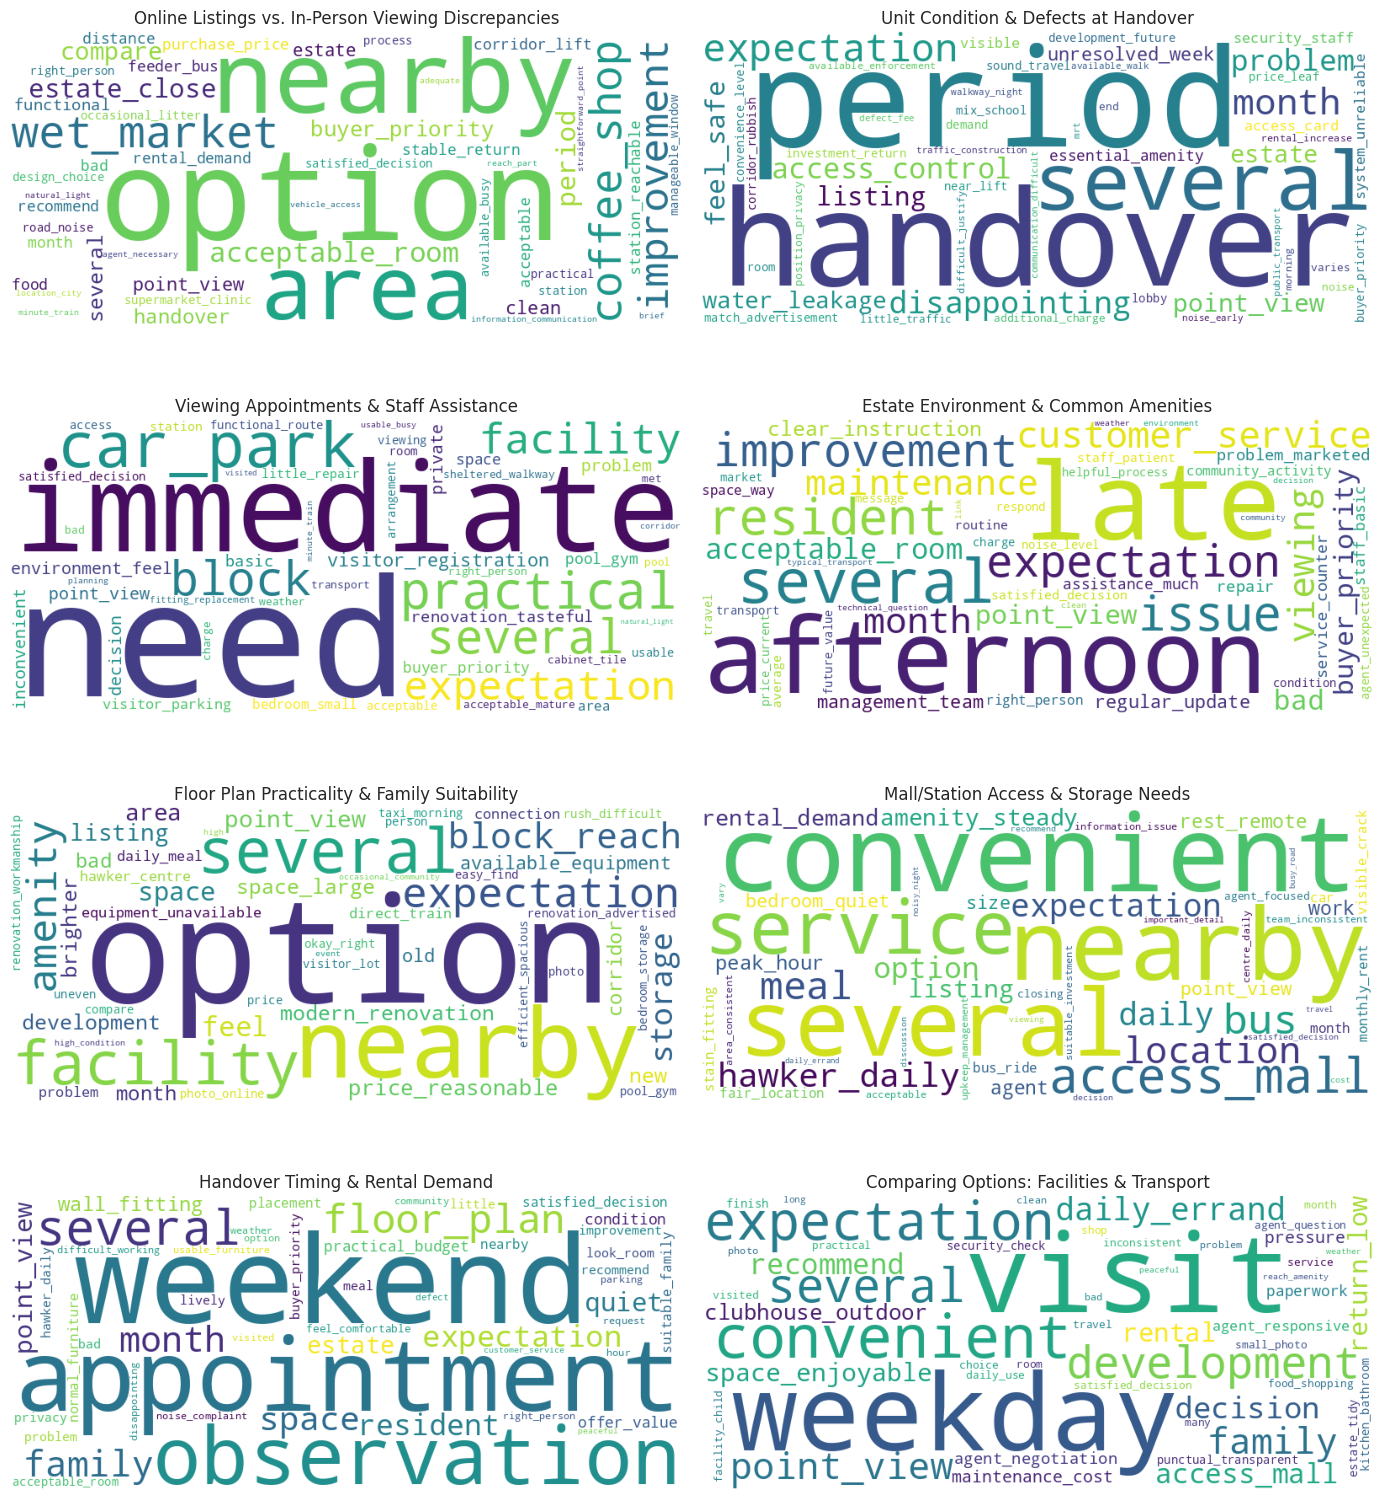

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.166439 -0.106277       1        1  12.678196
1      0.045895  0.047834       2        1  12.782136
2     -0.111614 -0.272224       3        1  11.918462
3     -0.238301 -0.007038       4        1  12.909067
4      0.217189 -0.080724       5        1  12.991600
5      0.157819  0.160546       6        1   9.209302
6     -0.142157 -0.004176       7        1  15.137492
7     -0.095269  0.262059       8        1  12.373745, topic_info=            Term        Freq       Total Category  logprob  loglift
21          need  556.000000  556.000000  Default  30.0000  30.0000
25         visit  539.000000  539.000000  Default  29.0000  29.0000
2           late  534.000000  534.000000  Default  28.0000  28.0000
26       weekday  515.000000  515.000000  Default  27.0000  27.0000
20     immediate  498.000000  498.000000  Default  26.0000  26.0000
..           ...         ...         ...      ...      ...      ...
152    recommend   32.969277  117.567801   Topic8  -4.2433   0.8182
99    point_view   43.163355  258.652821   Topic8  -3.9739   0.2991
15       several   49.486661  697.324343   Topic8  -3.8371  -0.5560
56   access_mall   30.270401  130.985800   Topic8  -4.3287   0.6247
22     practical   19.933621   96.579760   Topic8  -4.7464   0.5116

[368 rows x 6 columns], token_table=      Topic      Freq               Term
term                                    
5         1  0.441463         acceptable
5         3  0.283798         acceptable
5         6  0.268031         acceptable
291       3  0.965846  acceptable_mature
44        1  0.624057    acceptable_room
...     ...       ...                ...
302       2  0.985464      water_leakage
26        8  0.997519            weekday
19        7  0.998856            weekend
73        1  0.993163         wet_market
108       6  0.947655               work

[460 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5, 6, 7, 8])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [18]:
# Word clouds and pyLDAvis use best_lda -- not an old arbitrary ldamodel.
from wordcloud import WordCloud
fig, axes = plt.subplots(math.ceil(best_k / 2), 2, figsize=(14, 4 * math.ceil(best_k / 2)))
for topic_id, ax in zip(range(best_k), np.ravel(axes)):
    frequencies = dict(best_lda.show_topic(topic_id, topn=50))
    cloud = WordCloud(width=800, height=350, background_color='white', colormap='viridis').generate_from_frequencies(frequencies)
    ax.imshow(cloud); ax.set_title(TOPIC_LABELS[topic_id]); ax.axis('off')
for ax in np.ravel(axes)[best_k:]: ax.axis('off')
plt.tight_layout(); plt.show()

import pyLDAvis
import pyLDAvis.gensim_models
pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(best_lda, bow_corpus, dictionary, sort_topics=False)
vis

## 11.5 Sentence-Embedding Sanity Check (Optional, Exploratory)

LDA treats words as independent counts, so it can miss cases where two different words mean
the same thing (e.g. "wet_market" and "hawker_centre"). This section is a lightweight,
exploratory cross-check — NOT a replacement model — using a pretrained sentence-transformer
to see whether an independent embedding-based clustering agrees with the LDA topics.

**Method:** encode each cleaned review into a dense embedding using `all-MiniLM-L6-v2`, run KMeans
with k = `best_k` (the same number of topics as the final LDA model), then compare cluster labels
against `dominant_topic` using the Adjusted Rand Index (ARI) and a contingency table.

- ARI close to 1.0 -> strong agreement, supports confidence in the LDA topics
- ARI close to 0.0 -> low agreement, suggests LDA topics may be less robust than they appear
- This is exploratory support evidence only and does not change the final reported LDA topics/labels


In [17]:
!pip install -q sentence-transformers

from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

embed_model = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = embed_model.encode(reviews_model['Review_Text'].tolist(), show_progress_bar=True)

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
reviews_model['embedding_cluster'] = kmeans.fit_predict(embeddings)

ari = adjusted_rand_score(reviews_model['dominant_topic'], reviews_model['embedding_cluster'])
print(f"Adjusted Rand Index (LDA vs. sentence-embedding clusters): {ari:.3f}")

contingency = pd.crosstab(reviews_model['topic_label'], reviews_model['embedding_cluster'])
contingency


Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Adjusted Rand Index (LDA vs. sentence-embedding clusters): 0.103


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


embedding_cluster,0,1,2,3,4,5,6,7
topic_label,,,,,,,,
Comparing Options: Facilities & Transport,17,40,149,107,26,12,43,5
Estate Environment & Common Amenities,49,128,61,127,14,4,16,7
Floor Plan Practicality & Family Suitability,39,25,45,18,144,73,10,24
Handover Timing & Rental Demand,57,142,72,125,67,27,3,16
Mall/Station Access & Storage Needs,20,24,36,17,0,56,27,29
Online Listings vs. In-Person Viewing Discrepancies,18,20,98,12,42,76,62,22
Unit Condition & Defects at Handover,21,38,37,40,3,18,193,12
Viewing Appointments & Staff Assistance,2,12,43,31,159,129,10,1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Write-up and hand-off checklist

- Put the actual selected `k`, mean coherence, dataset coverage, initial/final row counts and every removal rule in Fion's slides/portfolio.
- Replace `TOPIC_LABELS` after checking top terms **and** representative reviews. Report the exact labels and no more than 2-3 decision-relevant findings.
- Report the Region, Property_Type, Reviewer_Type **and Year** topic-share tables together — all four use the same single fitted `best_lda` model, so topic labels are directly comparable across every breakdown.
- From the Year breakdown, explicitly name which topics are **common/stable across 2024-2026** (low std in the stability score) versus which are **emerging or fading** (high std) — this distinction is a required output of the temporal analysis, not optional.
- Use the Top 30 most-confident-review lists (Sections 10a-ii and 10b-ii) to pick 2-3 direct quotes per year and per region for slides — do not paraphrase; quote the actual `Review_Text`.
- Sanity-check year coverage before trusting the Year comparison: confirm 2024, 2025 and 2026 each have a reasonable review count (see the value-count table in Section 10a) so no conclusion rests on a thin partial year.
- Link each finding to an action, e.g. listing copy/highlight, buyer FAQ, agent training or campaign segmentation. Do not infer prices, demand or population sentiment from review volume alone.
- Report the sentence-embedding sanity check (ARI + contingency table) as supporting/contradicting exploratory evidence for LDA topic robustness — this is optional supplementary validation, not a required core evaluation step.
- State limitations: synthetic or non-representative reviews, missing sentiment validation, partial-year 2026 data, and LDA topics are exploratory associations rather than causal effects, and were cross-checked (not replaced) using sentence-embedding clustering as a secondary robustness signal.
- Ethical controls: remove personal data from public outputs, document source/permission, avoid targeting protected or vulnerable groups, validate misleading topic labels, and name an owner accountable for recommendations.
- Save only the final dataset, notebook, environment/package versions and `README.md` in the individual GitHub portfolio.


# AI Ethics

•	Privacy: Dataset comprised synthetic reviews; no personal identifiable information was used.

•	Fairness: Reviewer-type language overlapped with topic terms, posing a risk of bias in topic assignment.

•	Accuracy: Topic labels were human interpretations of statistical clusters, subject to labeller judgement.

•	Accountability: A reproducible global model with fixed seeds ensures traceability and verification.

•	Transparency: Coherence scores, representative reviews, and topic-word overlaps were disclosed to allow independent scrutiny.

